# Adult Income: feature engineering inside a pipeline

This notebook analyses the attached Feature-engine example using the UCI Adult Income dataset. It builds one reproducible scikit-learn pipeline that: (1) handles missing categorical and numeric values, (2) groups rare labels, (3) target-encodes categorical variables with decision trees, (4) discretises numeric variables with supervised decision trees, and (5) trains a gradient-boosting classifier.

The target is whether annual income is above 50K. Every learned preprocessing step is fitted on the training partition only, which prevents test-set information from leaking into the model.

## Why use a pipeline?

A pipeline keeps preprocessing and modelling together. At training time, each transformer learns its parameters from training rows. At prediction time, the same fitted transformations are applied in the same order to new rows. This makes cross-validation safer and prevents accidentally applying a different preprocessing recipe to test or production data.

In [1]:
import importlib.util,subprocess,sys
packages={"numpy":"numpy","pandas":"pandas","matplotlib":"matplotlib","seaborn":"seaborn","sklearn":"scikit-learn","feature_engine":"feature-engine"}
missing=[pkg for module,pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,"-m","pip","install",*missing])
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, roc_auc_score
from feature_engine import imputation as mdi
from feature_engine import discretisation as dsc
from feature_engine import encoding as ce
sns.set_theme(style="whitegrid",context="notebook")

## 1. Load the Adult Income data

The original example expects `adult.data` one directory above the notebook. This version searches common local locations and falls back to the public UCI repository if a local copy is not found. Downloading is attempted only when needed. The dataset has no header row, so column names are assigned explicitly.

In [2]:
column_names=['age','workclass','fnlwgt','education','education-num','marital-status','occupation','relationship','race','sex','capital-gain','capital-loss','hours-per-week','native-country','income']
local_paths=[Path("adult.data"),Path("../adult.data"),Path("feature-engineering/pipelines/adult.data"),Path("feature-engineering/adult.data")]
local_path=next((p for p in local_paths if p.exists()),None)
if local_path is not None:
    data=pd.read_csv(local_path,sep=",",names=column_names,skipinitialspace=True,na_values="?")
    source_description=str(local_path)
else:
    url="https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
    data=pd.read_csv(url,sep=",",names=column_names,skipinitialspace=True,na_values="?")
    source_description=url
print("Source:",source_description)
print("Shape:",data.shape)
display(data.head())

Source: https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data
Shape: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 2. Inspect types, missing values, and the target

The Adult data contains a mixture of numeric measurements and categorical labels. The `?` marker is converted to missing values. Before modelling, we standardise the target labels and inspect category cardinality. High-cardinality variables such as `native-country` and `occupation` benefit from rare-label grouping before encoding.

In [3]:
data=data.copy()
data["income"]=data["income"].astype(str).str.strip().str.replace(".","",regex=False)
data["income"]=data["income"].map({"<=50K":0,">50K":1})
if data["income"].isna().any(): raise ValueError("Unexpected income label found")
print("Target balance:")
display(data["income"].value_counts(normalize=True).rename(index={0:"<=50K",1:">50K"}).rename("share").to_frame())
display(pd.DataFrame({"dtype":data.dtypes.astype(str),"missing":data.isna().sum(),"missing_pct":(data.isna().mean()*100).round(2)}))
categorical=[c for c in data.columns if data[c].dtype=="object"]
numeric=[c for c in data.columns if c not in categorical+["income"]]
print("Categorical columns:",categorical)
print("Numeric columns:",numeric)
display(data[categorical].nunique(dropna=False).sort_values(ascending=False).rename("unique_values").to_frame())

Target balance:


,share
income,
<=50K,0.75919
>50K,0.24081


,dtype,missing,missing_pct
age,int64,0,0.00
workclass,object,1836,5.64
fnlwgt,int64,0,0.00
education,object,0,0.00
education-num,int64,0,0.00
marital-status,object,0,0.00
occupation,object,1843,5.66
relationship,object,0,0.00
race,object,0,0.00
sex,object,0,0.00


Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Numeric columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']


,unique_values
native-country,42
education,16
occupation,15
workclass,9
marital-status,7
relationship,6
race,5
sex,2


## 3. Explore the data

These plots show the target balance, numeric distributions, and selected categorical relationships. They are exploratory summaries; they do not imply that a category causes income. The model will learn transformations only after the train/test split.

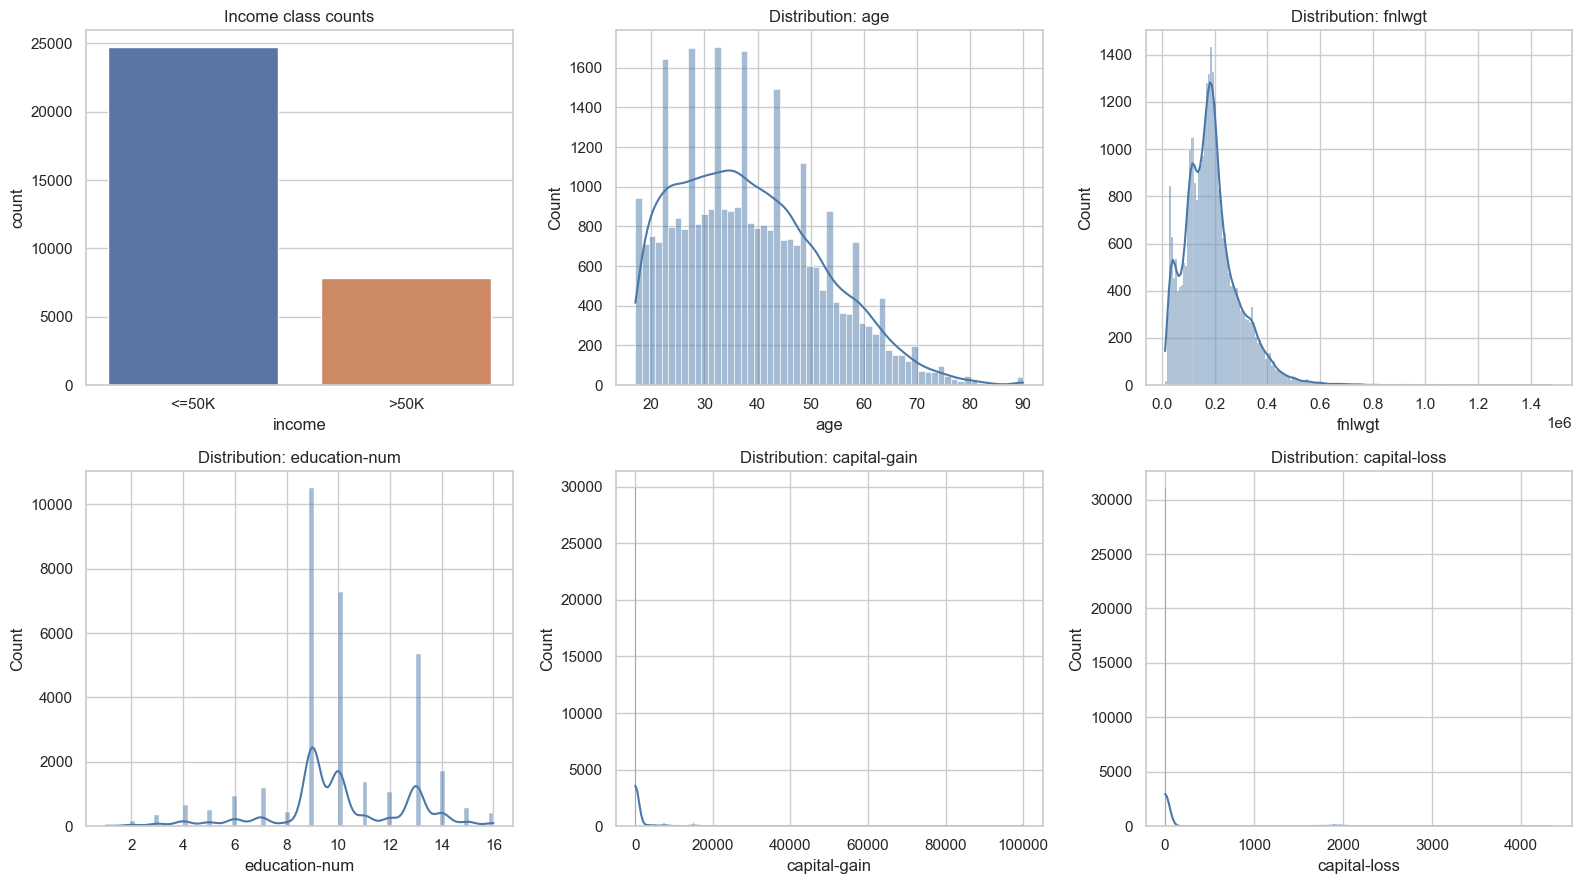

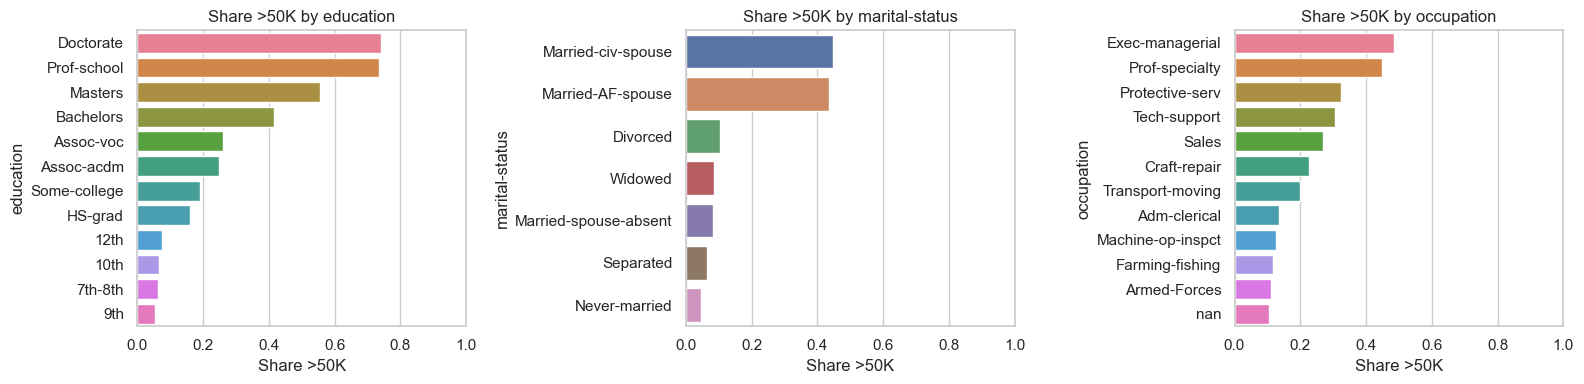

In [4]:
fig,axes=plt.subplots(2,3,figsize=(16,9))
sns.countplot(data=data,x="income",hue="income",legend=False,ax=axes[0,0]); axes[0,0].set_xticks([0,1],["<=50K",">50K"]); axes[0,0].set_title("Income class counts")
for ax,col in zip(axes.flat[1:],numeric[:5]):
    sns.histplot(data=data,x=col,kde=True,ax=ax,color="#4C78A8"); ax.set_title(f"Distribution: {col}")
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,col in zip(axes,["education","marital-status","occupation"]):
    rate=data.groupby(col,dropna=False)["income"].mean().sort_values(ascending=False).head(12)
    sns.barplot(x=rate.values,y=rate.index.astype(str),hue=rate.index.astype(str),legend=False,ax=ax); ax.set_title(f"Share >50K by {col}"); ax.set_xlim(0,1); ax.set_xlabel("Share >50K")
plt.tight_layout(); plt.show()

## 4. Split the target before fitting any transformer

The target is removed from `X`. Stratification preserves the approximate income-class proportion in both partitions. All imputation, rare-label grouping, target encoding, and tree-based discretisation will be fitted inside the pipeline on `X_train` and `y_train` only.

In [5]:
X=data.drop(columns=["income"]).copy()
y=data["income"].astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Train shape:",X_train.shape,"Test shape:",X_test.shape)
print("Train positive share:",round(y_train.mean(),3),"Test positive share:",round(y_test.mean(),3))

Train shape: (26048, 14) Test shape: (6513, 14)
Train positive share: 0.241 Test positive share: 0.241


## 5. Define the feature-engineering pipeline

The steps mirror the attached notebook but add explicit imputers and a modern, leakage-safe order:

1. `CategoricalImputer` replaces missing categorical labels with `Missing`.
2. `MeanMedianImputer` fills numeric missing values with training medians.
3. `RareLabelEncoder` groups categories that are too infrequent.
4. `DecisionTreeEncoder` converts categorical labels into target-informed probabilities.
5. `DecisionTreeDiscretiser` converts numeric values into target-informed finite predictions.
6. `GradientBoostingClassifier` learns the final income classifier.

Decision-tree encoders and discretisers are supervised. Putting them inside the pipeline ensures they learn only from each training fold during cross-validation.

In [6]:
income_pipe=Pipeline(steps=[
    ("categorical_imputer",mdi.CategoricalImputer(variables=categorical,fill_value="Missing")),
    ("numeric_imputer",mdi.MeanMedianImputer(imputation_method="median",variables=numeric)),
    ("rare_label_enc",ce.RareLabelEncoder(tol=0.01,n_categories=1,variables=categorical,replace_with="Rare")),
    ("categorical_tree_enc",ce.DecisionTreeEncoder(regression=False,variables=categorical,param_grid={"max_depth":[1,2,3]},random_state=42)),
    ("numeric_tree_disc",dsc.DecisionTreeDiscretiser(regression=False,variables=numeric,bin_output="prediction",precision=4,param_grid={"max_depth":[1,2,3]},random_state=42)),
    ("gbm",GradientBoostingClassifier(random_state=42))
])
income_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('categorical_imputer', ...), ('numeric_imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,imputation_method,'missing'
,fill_value,'Missing'
,variables,"['workclass', 'education', ...]"
,return_object,False
,ignore_format,False
,imputation_method,'median'
,variables,"['age', 'fnlwgt', ...]"


## 6. Fit the pipeline and transform the data

Calling `fit` runs every preprocessing step in order and then trains the classifier. Calling `transform` is not required separately because `Pipeline.predict` applies all transformations automatically. The fitted pipeline can therefore be saved and reused for future applicants with the same columns.

In [7]:
income_pipe.fit(X_train,y_train)
train_predictions=income_pipe.predict(X_train)
test_predictions=income_pipe.predict(X_test)
test_probabilities=income_pipe.predict_proba(X_test)[:,1]
print("Pipeline fitted successfully.")
print("Train accuracy:",round(accuracy_score(y_train,train_predictions),4))
print("Test accuracy:",round(accuracy_score(y_test,test_predictions),4))
print("Test F1:",round(f1_score(y_test,test_predictions),4))
print("Test ROC-AUC:",round(roc_auc_score(y_test,test_probabilities),4))

Pipeline fitted successfully.
Train accuracy: 0.8578
Test accuracy: 0.8653
Test F1: 0.6729
Test ROC-AUC: 0.9151


## 7. Evaluate errors and inspect model behavior

Accuracy alone can hide poor performance on the smaller `>50K` class. We report precision, recall, and F1, then display a confusion matrix. The model's probabilities are useful when a decision threshold other than 0.5 is appropriate for the application.

              precision    recall  f1-score   support

       <=50K       0.88      0.96      0.92      4945
        >50K       0.81      0.58      0.67      1568

    accuracy                           0.87      6513
   macro avg       0.84      0.77      0.79      6513
weighted avg       0.86      0.87      0.86      6513



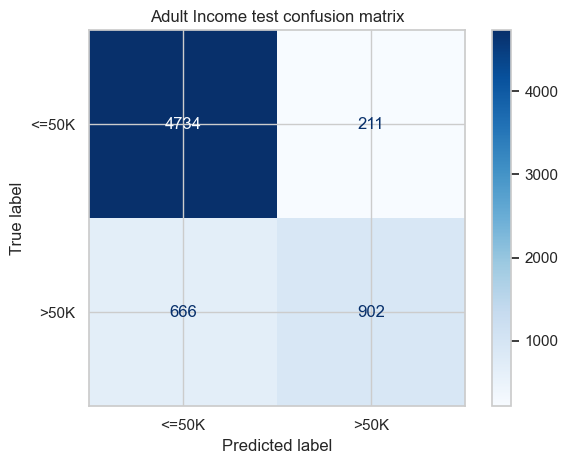

In [8]:
print(classification_report(y_test,test_predictions,target_names=["<=50K",">50K"]))
ConfusionMatrixDisplay.from_predictions(y_test,test_predictions,display_labels=["<=50K",">50K"],cmap="Blues")
plt.title("Adult Income test confusion matrix"); plt.tight_layout(); plt.show()

,importance
race,0.405926
education-num,0.221603
relationship,0.202762
capital-gain,0.080642
workclass,0.037873
sex,0.022043
capital-loss,0.021985
fnlwgt,0.002820
education,0.001631
occupation,0.001026


/var/folders/dx/zd4nxtxd4fsb__p09t61ld9w0000gn/T/ipykernel_4922/149262905.py:5: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#4C78A8'` for the same effect.

  sns.barplot(x=importance.head(15).values,y=importance.head(15).index,hue=importance.head(15).index,legend=False,color="#4C78A8")


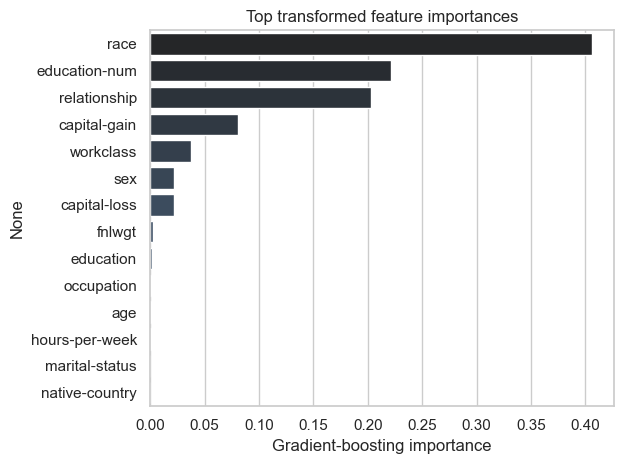

In [9]:
gbm=income_pipe.named_steps["gbm"]
feature_names=categorical+numeric
importance=pd.Series(gbm.feature_importances_,index=feature_names).sort_values(ascending=False)
display(importance.to_frame("importance").head(15))
sns.barplot(x=importance.head(15).values,y=importance.head(15).index,hue=importance.head(15).index,legend=False,color="#4C78A8")
plt.title("Top transformed feature importances"); plt.xlabel("Gradient-boosting importance"); plt.tight_layout(); plt.show()

## 8. Inspect learned preprocessing parameters

The fitted steps expose the information learned from training data. Reviewing these attributes helps confirm that missing values and rare categories were handled as intended. The exact learned categories and tree boundaries should be stored with the model artifact.

## 9. Practical limitations and next steps

- The Adult dataset contains survey categories and may have leading spaces, missing labels, and class imbalance. The notebook strips whitespace and treats missing values explicitly.
- Target-informed encoders can overfit. Keep them inside the pipeline and use cross-validation when tuning the model.
- `fnlwgt` is a survey weight, not necessarily a useful predictive measurement; evaluate whether it belongs in the final model.
- Feature importance is model-specific and does not prove causation.
- For production, validate incoming columns, monitor unseen categories and missingness, calibrate probabilities if needed, and save the complete fitted pipeline rather than individual transformers.

### Summary

This pipeline turns mixed Adult Income data into model-ready numeric features and trains a gradient-boosting classifier without leaking test information into preprocessing. It combines the workflow in the attached notebook with explicit missing-value handling, reproducible paths, richer metrics, and visual diagnostics.